In [1]:
import argparse
import sys
import contextlib
import logging
import os
import time
import traceback
from pathlib import Path
 
import numpy as np
import pandas as pd
import torch
from flwr.simulation import run_simulation
from sklearn.metrics import auc as sk_auc
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             roc_auc_score, roc_curve)
 
import config
import fl_basic4 as fl          # <- ganti jika nama file strategy/client-mu berbeda
from dataset import DROP_COLS, TARGET
from model import build_model
 
# ============================================================
# 0. KONFIGURASI RUNNER
# ============================================================
CLIENT_DIR = Path(r'C:\Users\s2\Documents\FIXRKI\bfprssprep\split\clients')
ALGOS = ['fedavg', 'fedprox', 'fedavgm', 'fedadam', 'fedpairwise']
BASELINE = 'fedavg'                      # pembanding untuk uji berpasangan
ORIG_OUT_DIR = Path(config.OUT_DIR)      # folder induk output = ORIG_OUT_DIR.parent
ORIG_SEED = int(config.SEED)
 
SEEDS = [42, 0, 123, 1337, 3407]
 
# True  = evaluasi memakai best_params.npz (val_loss terbaik) bila ada
# False = selalu memakai final_params.npz (bobot ronde terakhir)
USE_BEST = True
 
# metrik TEST (tanpa prefix) dan VALIDASI (prefix 'val_')
# 'ap' = Average Precision (ringkasan area di bawah PR curve)
METRIC_COLS_TEST = ['acc', 'prec', 'rec', 'f1', 'auc', 'ap', 'prauc',
                    'f1_macro_klien', 'f1_std_klien', 'total_MB', 'waktu_s']
METRIC_COLS_VAL = ['val_acc', 'val_prec', 'val_rec', 'val_f1', 'val_auc',
                   'val_ap', 'val_prauc', 'val_f1_macro_klien',
                   'val_f1_std_klien', 'gap_f1']
PAIRED_TEST = ('f1', 'auc', 'ap', 'prauc')
PAIRED_VAL = ('val_f1', 'val_auc', 'val_ap', 'val_prauc')
 
# kolom tabel per-client lengkap
PER_CLIENT_COLS = ['n', 'prevalensi', 'acc', 'prec', 'rec', 'f1', 'auc', 'ap', 'prauc']
METR_DASAR = ['acc', 'prec', 'rec', 'f1', 'auc', 'ap', 'prauc']
 
# ---- logging ----
VERBOSE = False                          # True = semua print tampil di konsol
LOG_DIR = ORIG_OUT_DIR.parent
LOG_DIR.mkdir(parents=True, exist_ok=True)
LOG_FLWR = LOG_DIR / 'flwrfullclient.log'
LOG_PRINTS = LOG_DIR / 'printsfullklient.log'
 
 
def setup_flwr_logging():
    """Console Flower hanya WARNING+; detail penuh ke file. Aman dipanggil berulang."""
    lg = logging.getLogger("flwr")
    for h in lg.handlers:
        if not isinstance(h, logging.FileHandler):
            h.setLevel(logging.WARNING)
    if not any(isinstance(h, logging.FileHandler) for h in lg.handlers):
        fh = logging.FileHandler(LOG_FLWR, encoding="utf-8")
        fh.setLevel(logging.INFO)
        fh.setFormatter(logging.Formatter("%(asctime)s %(levelname)s %(message)s"))
        lg.addHandler(fh)
    lg.setLevel(logging.INFO)
 
 
@contextlib.contextmanager
def quiet(logfile=None):
    """Alihkan print() ke file. Dinonaktifkan bila VERBOSE."""
    if VERBOSE:
        yield
        return
    with open(logfile or LOG_PRINTS, "a", encoding="utf-8") as f, \
            contextlib.redirect_stdout(f):
        yield
 
 
setup_flwr_logging()
 

c:\Users\s2\Documents\FIXRKI\.fed\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-26 15:47:42,443	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


In [2]:

# %%
# ============================================================
# 1. DATASET, MODUL & RINGKASAN DATA
# ============================================================
def setup_dataset():
    """Arahkan config ke folder dataset dan buang cache data lama."""
    if not CLIENT_DIR.is_dir():
        sys.exit(f"Folder dataset tidak ditemukan: {CLIENT_DIR}")
    config.CLIENT_DIR = CLIENT_DIR
    os.environ['FL_CLIENT_DIR'] = str(CLIENT_DIR)
    try:
        import ray
        if ray.is_initialized():
            ray.shutdown()
    except ImportError:
        pass
    clear = getattr(fl.load_data, 'cache_clear', None)
    if clear:
        clear()
    n_item = sum(1 for _ in CLIENT_DIR.iterdir())
    print(f"Dataset : {CLIENT_DIR} ({n_item} item)")
 
 
def show_modules():
    print(f"Modul FL: {fl.__name__} ({Path(fl.__file__).name})")
    cls = getattr(fl, 'FedCosinePairwise', None)
    if cls is not None:
        print(f"Agregasi pairwise dari modul: {cls.__module__}")
 
 
def available_algos(algos):
    known = getattr(fl, 'ALGOS', algos)
    ok = [a for a in algos if a in known]
    skip = [a for a in algos if a not in ok]
    if skip:
        print(f"[lewati] tidak ada di {fl.__name__}.ALGOS: {skip}")
    return ok
 
 
def data_summary():
    clients, scaler, feature_names = fl.load_data()
    n_clients = len(clients)
    n_fitur = fl.get_in_dim()
    assert n_fitur == len(feature_names), "Jumlah fitur tidak cocok dengan nama fitur"
 
    print("=" * 50)
    print(f"Jumlah client (state) : {n_clients}")
    print(f"Daftar state          : {fl.state_list()}")
    print(f"Target                : {TARGET}")
    print(f"Kolom dibuang         : {DROP_COLS}")
    print(f"Jumlah fitur          : {n_fitur}")
    print(f"Jumlah ronde          : {config.NUM_ROUNDS}")
    print(f"Client dilatih/ronde  : "
          f"{max(1, round(config.FRACTION_FIT * n_clients))} dari {n_clients}")
    print(f"Local epochs          : {config.LOCAL_EPOCHS}")
    print("=" * 50)
    for i, nama in enumerate(feature_names, 1):
        print(f"{i:>3}. {nama}")
 
    rows = {st: {
        'n_train':   len(c['y_train_t']),
        'n_val':     len(c['y_val_t']),
        'n_test':    len(c['y_test_t']),
        'pos_train': int(c['y_train_t'].sum()),
        'pos_val':   int(c['y_val_t'].sum()),
        'pos_test':  int(c['y_test_t'].sum()),
    } for st, c in clients.items()}
 
    ringkas = pd.DataFrame(rows).T
    ringkas.index.name = 'state'
    for s in ('train', 'val', 'test'):
        ringkas[f'pos_{s}_%'] = (100 * ringkas[f'pos_{s}'] / ringkas[f'n_{s}']).round(2)
 
    total = ringkas[[c for c in ringkas.columns if not c.endswith('%')]].sum()
    for s in ('train', 'val', 'test'):
        total[f'pos_{s}_%'] = round(100 * total[f'pos_{s}'] / total[f'n_{s}'], 2)
    ringkas.loc['TOTAL'] = total
 
    print("\nRingkasan per client:")
    print(ringkas.to_string())
 
    total_train = sum(len(c['y_train_t']) for c in clients.values())
    print("\nscaler.n_samples_seen_ vs total train:",
          scaler.n_samples_seen_, total_train, "(harus sama)")
    return n_clients
 
 
# %%
# ============================================================
# 2. JALANKAN SATU (ALGORITMA, SEED)
# ============================================================
def _tail(path, n=40):
    try:
        lines = Path(path).read_text(encoding='utf-8', errors='replace').splitlines()
        return "\n".join(lines[-n:])
    except FileNotFoundError:
        return None
 
 
def show_failure_logs(n=40):
    """Cetak ujung semua log agar penyebab simulasi gagal langsung terlihat."""
    print("\n[DIAGNOSTIK] simulasi tidak menghasilkan ronde yang selesai. "
          "Isi log terakhir:")
    for f in ('ronde_log.csv', 'final_params.npz'):
        for lokasi, d in (('run ini', config.OUT_DIR), ('folder output awal', ORIG_OUT_DIR)):
            print(f"{f:<18} di {lokasi:<20}: {'ADA' if (d / f).exists() else 'tidak ada'}")
    for nama, p in (('client_error.log (run ini)', config.OUT_DIR / 'client_error.log'),
                    ('client_error.log (folder output awal)', ORIG_OUT_DIR / 'client_error.log'),
                    ('flwr.log', LOG_FLWR),
                    ('prints.log', LOG_PRINTS)):
        txt = _tail(p, n)
        print(f"\n--- {nama}: {p} ---")
        print(txt if txt else "(tidak ada / kosong)")
 
 
def run_algo(algo, seed, n_clients, out_root):
    """Simulasi FL untuk satu algoritma & seed; output ke out_root/out_<algo>_s<seed>."""
    config.SEED = seed
    os.environ['FL_SEED'] = str(seed)
    config.OUT_DIR = out_root / f'out_{algo}_s{seed}'
    config.ensure_out_dir()
    # diwariskan ke worker Ray -> client_error.log masuk ke folder run ini
    os.environ['FL_OUT_DIR'] = str(config.OUT_DIR)
    for nama in ('final_params.npz', 'best_params.npz', 'ronde_log.csv'):
        (config.OUT_DIR / nama).unlink(missing_ok=True)
    print(f"\n########## {algo} | seed {seed} ##########")
    setup_flwr_logging()                    # jaga-jaga bila handler di-reset
    with quiet():                           # print() internal -> prints.log
        run_simulation(
            server_app=fl.make_server_app(algo),
            client_app=fl.make_client_app(),
            num_supernodes=n_clients,
            backend_config={"client_resources": {"num_cpus": 1, "num_gpus": 0.0}},
        )
    wajib = [config.OUT_DIR / 'final_params.npz', config.OUT_DIR / 'ronde_log.csv']
    if not all(p.exists() for p in wajib):
        show_failure_logs()
        raise RuntimeError(
            f"Simulasi {algo} seed {seed} tidak menyelesaikan satu ronde pun. "
            f"Lihat log di atas.")
 
 
def load_global_model(use_best=None):
    """Muat bobot dari run aktif: best_params.npz (bila USE_BEST) atau final_params.npz."""
    use_best = USE_BEST if use_best is None else use_best
    path = config.OUT_DIR / 'best_params.npz'
    if not (use_best and path.exists()):
        path = config.OUT_DIR / 'final_params.npz'
    if not path.exists():
        raise FileNotFoundError(
            f"{path} tidak ada: simulasi gagal sebelum ada ronde yang selesai. "
            f"Cek {config.OUT_DIR / 'client_error.log'}")
    d = np.load(path)
    w = [d[f'arr_{i}'] for i in range(len(d.files))]
    m = build_model(fl.get_in_dim(), seed=config.SEED).to(config.DEVICE)
    fl.set_weights(m, w)
    return m
 
 
# %%
# ============================================================
# 2b. METRIK DIAGNOSTIK: AUC-ROC, PR CURVE / AP  (split: val / test)
# ============================================================
def _to_prob(out):
    """Ubah output model (logit / prob / 2 kelas) menjadi P(kelas=1), shape (n,)."""
    out = np.asarray(out, dtype=np.float64)
    if out.ndim == 2 and out.shape[1] == 2:
        if out.min() < 0 or out.max() > 1 or not np.allclose(out.sum(1), 1, atol=1e-3):
            e = np.exp(out - out.max(1, keepdims=True))
            out = e / e.sum(1, keepdims=True)
        return out[:, 1]
    out = out.reshape(-1)
    if out.min() < 0.0 or out.max() > 1.0:          # logit -> sigmoid
        out = 1.0 / (1.0 + np.exp(-out))
    return out
 
 
def predict_proba_clients(model, split='test'):
    """Probabilitas prediksi & label per client. Kunci data: X_<split>_t, y_<split>_t."""
    clients, _, _ = fl.load_data()
    model.eval()
    ys, ps = {}, {}
    with torch.no_grad():
        for st, c in clients.items():
            xk, yk = f'X_{split}_t', f'y_{split}_t'
            if xk not in c:
                raise KeyError(f"Kunci '{xk}' tidak ada di data client. "
                               f"Kunci tersedia: {list(c.keys())}  -> sesuaikan xk.")
            out = model(c[xk].float().to(config.DEVICE)).detach().cpu().numpy()
            ps[st] = _to_prob(out)
            ys[st] = c[yk].detach().cpu().numpy().reshape(-1).astype(int)
    return ys, ps
 
 
def diagnostic_metrics(model, split='test'):
    """AUC-ROC & AP gabungan + AP/AUC per state + titik kurva ROC & PR gabungan."""
    ys, ps = predict_proba_clients(model, split)
    y_all = np.concatenate(list(ys.values()))
    p_all = np.concatenate(list(ps.values()))
 
    def _safe(fn, y, p):
        return float(fn(y, p)) if 0 < y.sum() < len(y) else float('nan')
 
    def _pr_auc(y, p):
        pr, rc, _ = precision_recall_curve(y, p)
        return float(sk_auc(rc, pr))
 
    per_state = pd.DataFrame({
        st: {'auc': _safe(roc_auc_score, ys[st], ps[st]),
             'ap': _safe(average_precision_score, ys[st], ps[st]),
             'prauc': _safe(_pr_auc, ys[st], ps[st]),
             'prevalensi': float(ys[st].mean())}
        for st in ys}).T
    per_state.index.name = 'state'
 
    fpr, tpr, _ = roc_curve(y_all, p_all)
    prec, rec, _ = precision_recall_curve(y_all, p_all)
    return {
        'auc': _safe(roc_auc_score, y_all, p_all),
        'ap': _safe(average_precision_score, y_all, p_all),
        'prevalensi': float(y_all.mean()),          # garis dasar PR (AP acak = prevalensi)
        'per_state': per_state,
        'roc': (fpr, tpr),
        'pr': (rec, prec),
    }
 
 
def _wavg(s, w):
    """Rata-rata berbobot yang melewati NaN (mis. AUC state satu-kelas)."""
    ok = s.notna()
    if not ok.any() or w[ok].sum() <= 0:
        return float('nan')
    return float((s[ok] * w[ok]).sum() / w[ok].sum())
 
 
def with_summary_rows(tabel, pooled=None):
    """Tambah baris MAKRO, BERBOBOT (bobot n) dan POOLED (semua data digabung)."""
    metr = [c for c in METR_DASAR if c in tabel.columns]
    w = tabel['n'].astype(float)
    rows = {
        'MAKRO': {**tabel[metr].mean().to_dict(), 'n': w.sum(),
                  'prevalensi': float(tabel['prevalensi'].mean())},
        'BERBOBOT': {**{c: _wavg(tabel[c], w) for c in metr}, 'n': w.sum(),
                     'prevalensi': _wavg(tabel['prevalensi'], w)},
    }
    if pooled:
        rows['POOLED'] = {**{c: pooled[c] for c in metr + ['prevalensi']
                             if c in pooled}, 'n': w.sum()}
    extra = pd.DataFrame(rows).T.reindex(columns=tabel.columns)
    extra.index.name = tabel.index.name
    return pd.concat([tabel, extra])
 
 
def per_client_lengkap(tabs, per_seed, algos, prefix=''):
    """Per algoritma: tabel per-client (rata-rata antar seed) + baris ringkasan.
    prefix='' untuk test, 'val_' untuk validasi (kolom pooled di per_seed)."""
    hasil = {}
    for algo in algos:
        dfs = [tabs[k] for k in tabs if k[0] == algo]
        if not dfs:
            continue
        rata = pd.concat(dfs).groupby(level=0, sort=False).mean()
        ps = per_seed.xs(algo, level='algoritma')
        pooled = {c: float(ps[f'{prefix}{c}'].mean())
                  for c in METR_DASAR + ['prevalensi']
                  if f'{prefix}{c}' in ps.columns}
        hasil[algo] = with_summary_rows(rata, pooled)
    return hasil
 
 
def eval_split(model, split):
    """Evaluasi lengkap satu split ('val' / 'test') pada model global.
    Return: (dict metrik pooled, DataFrame per client LENGKAP, diag)."""
    pooled = fl.evaluate_pooled(model, split=split)
    df = fl.evaluate_on_clients(model, split=split)
    diag = diagnostic_metrics(model, split)
 
    rec, prec = diag['pr']
    pr_auc = float(sk_auc(rec, prec)) if len(rec) > 1 else float('nan')
 
    m = {k: float(v) for k, v in pooled.items()
         if np.isscalar(v) and v is not None}
    m.update({
        'auc':            diag['auc'],      # selalu dari diagnostic (konsisten)
        'ap':             diag['ap'],
        'prauc':          pr_auc,
        'prevalensi':     diag['prevalensi'],
        'f1_macro_klien': float(df['f1'].mean()),
        'f1_std_klien':   float(df['f1'].std()),
    })
    full = df.rename(columns={f'n_{split}': 'n'}).join(
        diag['per_state'][['prevalensi', 'ap', 'prauc']])
    full = full[[c for c in PER_CLIENT_COLS if c in full.columns]]
    return m, full, diag
 
 
def report_split(model, split):
    """Cetak hasil satu split untuk mode --algo."""
    judul = {'val': 'VALIDASI', 'test': 'TEST'}.get(split, split.upper())
    print(f"\n----- Hasil {judul}: semua client, semua metrik -----")
    m, full, diag = eval_split(model, split)
    print(with_summary_rows(full, m).round(4).to_string())
    metr = [c for c in METR_DASAR if c in full.columns]
    print("\nStd antar client:")
    print(full[metr].std().round(4).to_string())
    print(f"\nAP/PR-AUC acak = prevalensi {diag['prevalensi']:.4f}")
 
 
def run_single(algo, seeds, n_clients, out_root):
    try:
        for seed in seeds:
            run_algo(algo, seed, n_clients, out_root)
 
            rep, ronde = fl.bandwidth_report()
            print(ronde.round(4).to_string(index=False))
 
            model = load_global_model()
            report_split(model, 'val')
            report_split(model, 'test')
    finally:
        config.SEED = ORIG_SEED
 
 
# %%
# ============================================================
# 3. KOMPARASI
# ============================================================
def collect_result(secs):
    """Kumpulkan hasil satu run: metrik val + test, bandwidth, log ronde."""
    model = load_global_model()
    m_te, df_te, diag_te = eval_split(model, 'test')
    m_va, df_va, diag_va = eval_split(model, 'val')
    ronde = pd.read_csv(config.OUT_DIR / 'ronde_log.csv').reset_index(drop=True)
    bw, _ = fl.bandwidth_report(verbose=False)
 
    # --- log validasi per ronde (aman bila kosong / semua NaN) ---
    f1 = ronde['f1'].astype(float)
    val_akhir = float(f1.iloc[-1]) if len(f1) else float('nan')
    if f1.notna().any():
        best = f1.idxmax()
        val_best, best_round = float(f1[best]), int(ronde.loc[best, 'round'])
    else:
        val_best, best_round = float('nan'), -1
 
    row = {
        **m_te,                                         # TEST (tanpa prefix)
        **{f'val_{k}': v for k, v in m_va.items()},     # VALIDASI (prefix val_)
        'gap_f1':           m_va['f1'] - m_te['f1'],    # val - test (selisih generalisasi)
        'ronde_val_f1_akhir':   val_akhir,              # dari ronde_log (rata-rata berbobot)
        'ronde_val_f1_terbaik': val_best,
        'ronde_terbaik':        best_round,
        'ronde_dijalankan':     int(len(ronde)),
        'ronde_terbaik_loss':   (int(ronde.loc[ronde['val_loss'].astype(float).idxmin(), 'round'])
                                 if ronde['val_loss'].astype(float).notna().any() else -1),
        'total_MB':         float(bw['total_MB']),
        'waktu_s':          round(secs, 1),
    }
    return row, df_te, df_va, ronde, diag_te, diag_va
 
 
def _fmt(mean, std, n, nd=4):
    if n < 2 or pd.isna(std):
        return f"{mean:.{nd}f}"
    return f"{mean:.{nd}f} ± {std:.{nd}f}"
 
 
def summarize_seeds(per_seed, cols_pref, sort_col):
    cols = [c for c in cols_pref if c in per_seed.columns]
    g = per_seed.groupby(level='algoritma')[cols]
    mean, std = g.mean(), g.std()
    n = g.size().rename('n_seed')
 
    num = pd.concat({'mean': mean, 'std': std}, axis=1)
    num.columns = [f'{c}_{stat}' for stat, c in num.columns]
    num.insert(0, 'n_seed', n)
    num = num.sort_values(f'{sort_col}_mean', ascending=False)
 
    tampil = pd.DataFrame(index=num.index)
    tampil['n_seed'] = num['n_seed']
    for c in cols:
        nd = 2 if c in ('total_MB', 'waktu_s') else 4
        tampil[c] = [_fmt(num.loc[a, f'{c}_mean'], num.loc[a, f'{c}_std'],
                          int(num.loc[a, 'n_seed']), nd) for a in num.index]
    return num, tampil
 
 
def _pvalue(d):
    if len(d) < 3 or float(d.std()) == 0.0:
        return float('nan')
    try:
        from scipy import stats
    except ImportError:
        return float('nan')
    return float(stats.ttest_1samp(d, 0.0).pvalue)

Modul FL: fl_basic4 (fl_basic4.py)
Agregasi pairwise dari modul: aggregation4
Dataset : C:\Users\s2\Documents\FIXRKI\bfprssprep\split\clients (45 item)
Jumlah client (state) : 44
Daftar state          : [1, 2, 4, 5, 8, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 22, 23, 24, 25, 26, 27, 29, 30, 31, 33, 34, 35, 36, 37, 38, 39, 40, 41, 44, 45, 46, 48, 49, 50, 51, 53, 54, 55, 56]
Target                : _michd
Kolom dibuang         : ['iyear', '_state', 'cvdinfr4', 'cvdcrhd4']
Jumlah fitur          : 69
Jumlah ronde          : 10
Client dilatih/ronde  : 44 dari 44
Local epochs          : 5
  1. sexvar
  2. _age80
  3. _educag
  4. income3
  5. veteran3
  6. children
  7. _urbstat
  8. _bmi5
  9. diabete4
 10. medcost1
 11. checkup1
 12. genhlth
 13. physhlth
 14. menthlth
 15. exerany2
 16. cvdstrk3
 17. chcscnc1
 18. chcocnc1
 19. chccopd3
 20. addepev3
 21. chckdny2
 22. havarth4
 23. diabage4
 24. deaf
 25. blind
 26. decide
 27. diffwalk
 28. diffdres
 29. diffalon
 30. _rfbing6
 31. drnka

[selesai] fedavg s42: VAL F1 0.4857 AUC 0.7471 AP 0.4441 | TEST F1 0.4682 AUC 0.7403 AP 0.4329 | 34.99 MB | 70.3 s

########## fedprox | seed 42 ##########


[selesai] fedprox s42: VAL F1 0.4896 AUC 0.7524 AP 0.4531 | TEST F1 0.4739 AUC 0.7461 AP 0.4437 | 34.99 MB | 93.7 s

########## fedavgm | seed 42 ##########


[selesai] fedavgm s42: VAL F1 0.4857 AUC 0.7471 AP 0.4441 | TEST F1 0.4682 AUC 0.7403 AP 0.4329 | 34.99 MB | 124.3 s

########## fedadam | seed 42 ##########


[selesai] fedadam s42: VAL F1 0.4841 AUC 0.7448 AP 0.4441 | TEST F1 0.4635 AUC 0.7373 AP 0.4314 | 34.99 MB | 127.1 s

########## fedpairwise | seed 42 ##########


...

[selesai] fedavg s3407: VAL F1 0.4838 AUC 0.7456 AP 0.4441 | TEST F1 0.4696 AUC 0.7400 AP 0.4338 | 34.99 MB | 70.3 s

########## fedprox | seed 3407 ##########


[selesai] fedprox s3407: VAL F1 0.4875 AUC 0.7508 AP 0.4527 | TEST F1 0.4730 AUC 0.7457 AP 0.4428 | 34.99 MB | 87.6 s

########## fedavgm | seed 3407 ##########


[selesai] fedavgm s3407: VAL F1 0.4838 AUC 0.7456 AP 0.4441 | TEST F1 0.4696 AUC 0.7400 AP 0.4338 | 34.99 MB | 68.4 s

########## fedadam | seed 3407 ##########


[selesai] fedadam s3407: VAL F1 0.4820 AUC 0.7442 AP 0.4428 | TEST F1 0.4644 AUC 0.7377 AP 0.4293 | 34.99 MB | 68.4 s

########## fedpairwise | seed 3407 ##########


[selesai] fedpairwise s3407: VAL F1 0.4855 AUC 0.7477 AP 0.4497 | TEST F1 0.4688 AUC 0.7423 AP 0.4391 | 34.99 MB | 72.3 s

PERBANDINGAN AGREGASI - TEST  (rata-rata ± std antar seed; urut F1)
             n_seed              acc             prec              rec               f1              auc               ap            prauc   f1_macro_klien     f1_std_klien      total_MB        waktu_s
algoritma                                                                                                                                                                                                
fedprox           5  0.6848 ± 0.0012  0.3632 ± 0.0015  0.6729 ± 0.0069  0.4717 ± 0.0027  0.7447 ± 0.0026  0.4421 ± 0.0048  0.4420 ± 0.0048  0.4699 ± 0.0029  0.0407 ± 0.0009  34.99 ± 0.00   93.06 ± 3.39
fedpairwise       5  0.6852 ± 0.0020  0.3621 ± 0.0023  0.6628 ± 0.0086  0.4683 ± 0.0035  0.7414 ± 0.0031  0.4378 ± 0.0058  0.4377 ± 0.0058  0.4674 ± 0.0042  0.0405 ± 0.0017  34.99 ± 0.00  80.52 ± 22.60
f

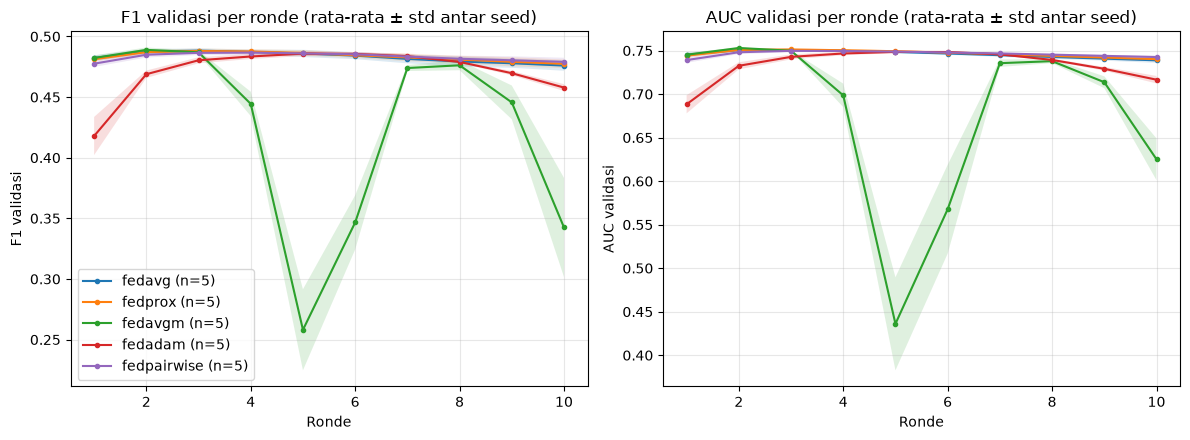

Grafik disimpan: C:\Users\s2\Documents\FIXRKI\FIXbanget\baselinefed\withEarlyStopping\kurva_roc_pr_val.png


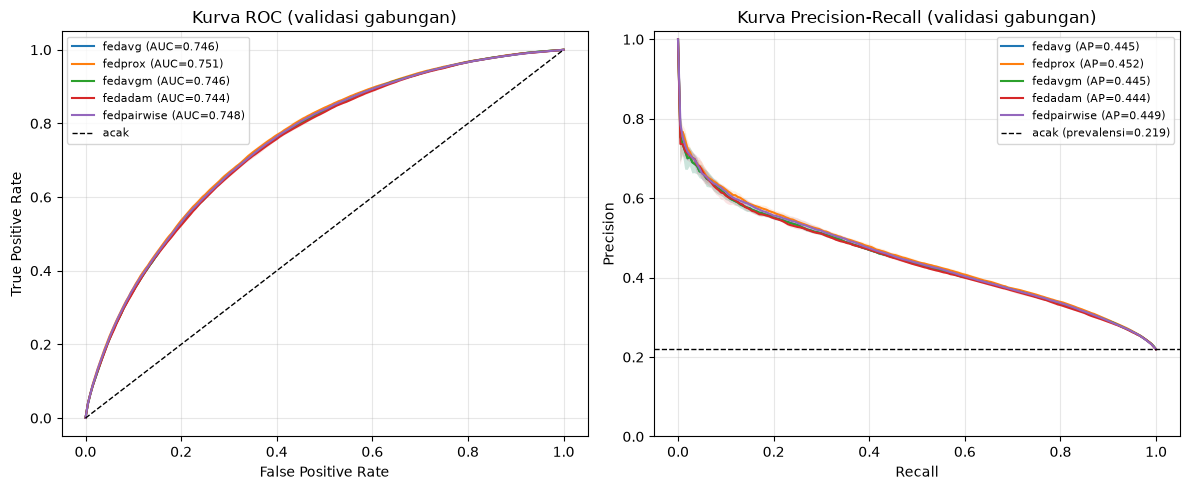

Grafik disimpan: C:\Users\s2\Documents\FIXRKI\FIXbanget\baselinefed\withEarlyStopping\kurva_roc_pr_test.png


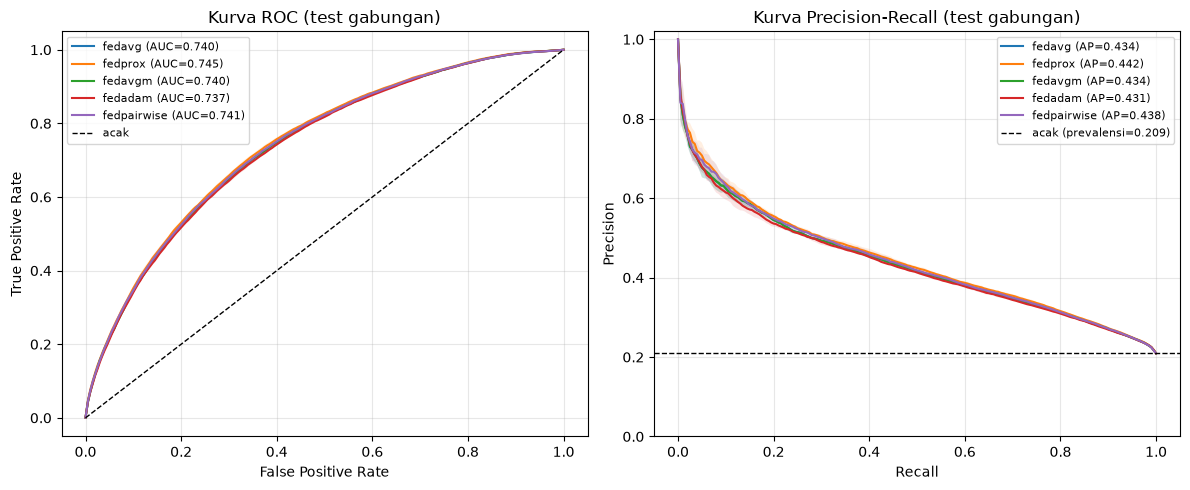

In [3]:

def paired_vs_baseline(per_seed, baseline, metrics):
    algos = list(per_seed.index.get_level_values('algoritma').unique())
    if baseline not in algos:
        return None
    base = per_seed.xs(baseline, level='algoritma')
    out = []
    for algo in algos:
        if algo == baseline:
            continue
        cur = per_seed.xs(algo, level='algoritma')
        seeds = base.index.intersection(cur.index)
        if len(seeds) == 0:
            continue
        row = {'algoritma': algo, 'n_seed': len(seeds)}
        for m in metrics:
            d = (cur.loc[seeds, m] - base.loc[seeds, m]).astype(float)
            row[f'd{m}_mean'] = float(d.mean())
            row[f'd{m}_std'] = float(d.std()) if len(d) > 1 else float('nan')
            row[f'{m}_menang'] = f"{int((d > 0).sum())}/{len(d)}"
            row[f'{m}_p'] = _pvalue(d)
        out.append(row)
    return pd.DataFrame(out).set_index('algoritma') if out else None
 
 
def _mean_by_algo(store, algos, getter=lambda x: x):
    """Rata-rata antar seed per algoritma untuk dict {(algo, seed): objek}."""
    return pd.DataFrame({
        algo: pd.concat([getter(store[k]) for k in store if k[0] == algo],
                        axis=1).mean(axis=1)
        for algo in algos
    })
 
 
def _get_plt():
    try:
        import matplotlib
        if 'ipykernel' not in sys.modules:
            matplotlib.use('Agg')
        import matplotlib.pyplot as plt
        return plt
    except ImportError:
        print("[lewati grafik] matplotlib belum terpasang (pip install matplotlib)")
        return None
 
 
def _finish(plt, fig, out_path):
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    print(f"Grafik disimpan: {out_path}")
    if 'ipykernel' in sys.modules:
        plt.show()
    else:
        plt.close(fig)
 
 
def plot_curves(kurva, out_path):
    """F1 & AUC validasi per ronde: rata-rata antar seed, pita = ± std."""
    plt = _get_plt()
    if plt is None:
        return
    per_algo = {}
    for (algo, _), ronde in kurva.items():
        per_algo.setdefault(algo, []).append(ronde)
 
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, col, judul in zip(axes, ('f1', 'auc'), ('F1 validasi', 'AUC validasi')):
        for algo, rs in per_algo.items():
            m = pd.concat([r.set_index('round')[col] for r in rs], axis=1)
            mu, sd = m.mean(axis=1), m.std(axis=1)
            ax.plot(mu.index, mu.values, marker='o', ms=3,
                    label=f'{algo} (n={len(rs)})')
            if len(rs) > 1:
                ax.fill_between(mu.index, (mu - sd).values, (mu + sd).values, alpha=0.15)
        ax.set_xlabel('Ronde')
        ax.set_ylabel(judul)
        ax.set_title(f'{judul} per ronde (rata-rata ± std antar seed)')
        ax.grid(alpha=0.3)
    axes[0].legend()
    _finish(plt, fig, out_path)
 
 
def plot_roc_pr(diags, out_path, nama_split='test'):
    """Kurva ROC & PR gabungan: rata-rata antar seed pada grid sama, pita = ± std."""
    plt = _get_plt()
    if plt is None:
        return
    per_algo = {}
    for (algo, _), d in diags.items():
        per_algo.setdefault(algo, []).append(d)
 
    grid = np.linspace(0, 1, 201)
    fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 5))
 
    for algo, ds in per_algo.items():
        tprs = np.array([np.interp(grid, *d['roc']) for d in ds])
        # PR: recall menurun -> balik urutan agar np.interp valid
        precs = np.array([np.interp(grid, d['pr'][0][::-1], d['pr'][1][::-1]) for d in ds])
        auc_m = np.nanmean([d['auc'] for d in ds])
        ap_m = np.nanmean([d['ap'] for d in ds])
 
        mu = tprs.mean(0)
        ax_roc.plot(grid, mu, label=f'{algo} (AUC={auc_m:.3f})')
        mu_p = precs.mean(0)
        ax_pr.plot(grid, mu_p, label=f'{algo} (AP={ap_m:.3f})')
        if len(ds) > 1:
            sd = tprs.std(0, ddof=1)
            ax_roc.fill_between(grid, mu - sd, mu + sd, alpha=0.12)
            sd_p = precs.std(0, ddof=1)
            ax_pr.fill_between(grid, mu_p - sd_p, mu_p + sd_p, alpha=0.12)
 
    prev = np.mean([d['prevalensi'] for ds in per_algo.values() for d in ds])
    ax_roc.plot([0, 1], [0, 1], 'k--', lw=1, label='acak')
    ax_pr.axhline(prev, color='k', ls='--', lw=1, label=f'acak (prevalensi={prev:.3f})')
 
    ax_roc.set(xlabel='False Positive Rate', ylabel='True Positive Rate',
               title=f'Kurva ROC ({nama_split} gabungan)')
    ax_pr.set(xlabel='Recall', ylabel='Precision',
              title=f'Kurva Precision-Recall ({nama_split} gabungan)', ylim=(0, 1.02))
    for ax in (ax_roc, ax_pr):
        ax.grid(alpha=0.3)
        ax.legend(loc='best', fontsize=8)
    _finish(plt, fig, out_path)
 
 
def run_compare(algos, seeds, n_clients, out_root):
    rows, kurva = {}, {}
    tab_te, tab_va, diag_te, diag_va = {}, {}, {}, {}
    total_run = len(algos) * len(seeds)
    print(f"\nKomparasi: {len(algos)} algoritma x {len(seeds)} seed = {total_run} run")
    print(f"Seed: {seeds}")
    print(f"Log detail: {LOG_FLWR} | {LOG_PRINTS}")
 
    try:
        for seed in seeds:
            for algo in algos:
                t0 = time.perf_counter()
                try:
                    run_algo(algo, seed, n_clients, out_root)
                    row, tabt, tabv, ronde, dte, dva = collect_result(
                        time.perf_counter() - t0)
                except Exception:
                    print(f"[GAGAL] {algo} seed {seed}:\n{traceback.format_exc()}")
                    continue
                key = (algo, seed)
                rows[key], kurva[key] = row, ronde
                tab_te[key], tab_va[key] = tabt, tabv
                diag_te[key], diag_va[key] = dte, dva
                print(f"[selesai] {algo} s{seed}: "
                      f"VAL F1 {row['val_f1']:.4f} AUC {row['val_auc']:.4f} AP {row['val_ap']:.4f} | "
                      f"TEST F1 {row['f1']:.4f} AUC {row['auc']:.4f} AP {row['ap']:.4f} | "
                      f"{row['total_MB']:.2f} MB | {row['waktu_s']} s")
    finally:
        config.SEED = ORIG_SEED
 
    if not rows:
        sys.exit("Tidak ada run yang berhasil.")
 
    idx = pd.MultiIndex.from_tuples(list(rows.keys()), names=['algoritma', 'seed'])
    per_seed = pd.DataFrame(list(rows.values()), index=idx)
 
    num, tampil_te = summarize_seeds(per_seed, METRIC_COLS_TEST, 'f1')
    num_va, tampil_va = summarize_seeds(per_seed, METRIC_COLS_VAL, 'val_f1')
    pair_te = paired_vs_baseline(per_seed, BASELINE, PAIRED_TEST)
    pair_va = paired_vs_baseline(per_seed, BASELINE, PAIRED_VAL)
 
    per_klien_te = _mean_by_algo(tab_te, num.index, lambda d: d['f1'])
    per_klien_te.loc['MAKRO'] = per_klien_te.mean()
    per_klien_va = _mean_by_algo(tab_va, num.index, lambda d: d['f1'])
    per_klien_va.loc['MAKRO'] = per_klien_va.mean()
 
    get_ap = lambda d: d['ap']
    ap_te = _mean_by_algo(tab_te, num.index, get_ap)
    ap_te.loc['MAKRO'] = ap_te.mean()
    ap_va = _mean_by_algo(tab_va, num.index, get_ap)
    ap_va.loc['MAKRO'] = ap_va.mean()
 
    print("\n" + "=" * 70)
    print("PERBANDINGAN AGREGASI - TEST  (rata-rata ± std antar seed; urut F1)")
    print("=" * 70)
    print(tampil_te.to_string())
 
    print("\n" + "=" * 70)
    print("PERBANDINGAN AGREGASI - VALIDASI  (model final; urut F1 validasi)")
    print("gap_f1 = F1 validasi - F1 test (besar = beda distribusi val/test)")
    print("=" * 70)
    print(tampil_va.to_string())
 
    print("\nHasil per seed (VALIDASI: F1 | AUC | AP):")
    print(per_seed[['val_f1', 'val_auc', 'val_ap']].round(4).unstack('seed').to_string())
    print("\nHasil per seed (TEST: F1 | AUC | AP):")
    print(per_seed[['f1', 'auc', 'ap']].round(4).unstack('seed').to_string())
 
    for nama, pair in (('VALIDASI', pair_va), ('TEST', pair_te)):
        if pair is not None:
            print(f"\nSelisih {nama} terhadap {BASELINE} pada seed yang sama "
                  f"(positif = lebih baik dari {BASELINE}):")
            print(pair.round(4).to_string())
    if pair_te is not None and int(pair_te['n_seed'].min()) < 5:
        print("Catatan: dengan <5 seed uji-t lemah; jangan terlalu bergantung "
              "pada p-value. Lihat kolom *_menang dan konsistensi arah selisih.")
    if pair_te is None and len(seeds) > 1:
        print(f"\n[uji berpasangan dilewati] baseline '{BASELINE}' tidak ikut/ gagal.")
 
    print("\nF1 validasi per state (rata-rata antar seed):")
    print(per_klien_va.round(4).to_string())
    print("\nF1 test per state (rata-rata antar seed):")
    print(per_klien_te.round(4).to_string())
    print("\nAP validasi per state (rata-rata antar seed):")
    print(ap_va.round(4).to_string())
    print("\nAP test per state (rata-rata antar seed):")
    print(ap_te.round(4).to_string())
 
    lengkap_va = per_client_lengkap(tab_va, per_seed, num.index, 'val_')
    lengkap_te = per_client_lengkap(tab_te, per_seed, num.index, '')
    for nama, lengkap in (('VALIDASI', lengkap_va), ('TEST', lengkap_te)):
        print("\n" + "=" * 70)
        print(f"EVALUASI SELURUH CLIENT - {nama} (rata-rata antar seed)")
        print("kolom: n, prevalensi, acc, prec, rec, f1, auc, ap, prauc")
        print("baris: tiap state + MAKRO, BERBOBOT, POOLED")
        print("=" * 70)
        for algo, t in lengkap.items():
            print(f"\n[{algo}]")
            print(t.round(4).to_string())
        print(f"\nRingkasan MAKRO antar client - {nama}:")
        print(pd.DataFrame({a: t.loc['MAKRO', METR_DASAR]
                            for a, t in lengkap.items()}).T.round(4).to_string())
        print(f"\nRingkasan POOLED - {nama}:")
        print(pd.DataFrame({a: t.loc['POOLED', METR_DASAR]
                            for a, t in lengkap.items()}).T.round(4).to_string())
 
    print(f"\nTerbaik F1 validasi       : {num_va['val_f1_mean'].idxmax()}")
    print(f"Terbaik F1 test           : {num['f1_mean'].idxmax()}")
    print(f"Terbaik AUC test          : {num['auc_mean'].idxmax()}")
    print(f"Terbaik AP test           : {num['ap_mean'].idxmax()}")
    if len(seeds) > 1:
        print(f"Paling stabil antar seed  : {num['f1_std'].idxmin()} (std F1 test terkecil)")
    print(f"Paling merata antar state : {num['f1_std_klien_mean'].idxmin()}")
    mb = num['total_MB_mean']
    if (mb.max() - mb.min()) > 0.01 * mb.max():
        print(f"Bandwidth terkecil        : {mb.idxmin()}")
    else:
        print("Bandwidth                 : sama untuk semua algoritma (ukuran parameter sama)")
 
    out_root.mkdir(parents=True, exist_ok=True)
    per_seed.to_csv(out_root / 'perbandingan_per_seed.csv')
    num.to_csv(out_root / 'perbandingan_ringkasan_test.csv')
    num_va.to_csv(out_root / 'perbandingan_ringkasan_val.csv')
    per_klien_te.to_csv(out_root / 'perbandingan_f1_per_client_test.csv')
    per_klien_va.to_csv(out_root / 'perbandingan_f1_per_client_val.csv')
    ap_te.to_csv(out_root / 'perbandingan_ap_per_client_test.csv')
    ap_va.to_csv(out_root / 'perbandingan_ap_per_client_val.csv')
    if pair_te is not None:
        pair_te.to_csv(out_root / 'perbandingan_berpasangan_test.csv')
    if pair_va is not None:
        pair_va.to_csv(out_root / 'perbandingan_berpasangan_val.csv')
    for nama, lengkap in (('val', lengkap_va), ('test', lengkap_te)):
        if lengkap:
            pd.concat(lengkap, names=['algoritma', 'state']).to_csv(
                out_root / f'perbandingan_per_client_lengkap_{nama}.csv')
    print(f"\nCSV disimpan di: {out_root}")
 
    plot_curves(kurva, out_root / 'kurva_validasi_per_ronde.png')
    plot_roc_pr(diag_va, out_root / 'kurva_roc_pr_val.png', 'validasi')
    plot_roc_pr(diag_te, out_root / 'kurva_roc_pr_test.png', 'test')
    return per_seed, num
 
 
# %%
# ============================================================
# 4. ENTRY POINT  (guard wajib untuk Ray/multiprocessing di Windows)
# ============================================================
def main(argv=None):
    ap = argparse.ArgumentParser(description="Simulasi Federated Learning")
    ap.add_argument('--algo', default=None, choices=ALGOS,
                    help="jalankan satu algoritma saja (tanpa komparasi)")
    ap.add_argument('--compare', action='store_true',
                    help="komparasi (default bila --algo tidak diberikan)")
    ap.add_argument('--algos', nargs='+', choices=ALGOS, default=ALGOS,
                    help="daftar algoritma untuk komparasi")
    ap.add_argument('--seeds', nargs='+', type=int, default=None,
                    help="timpa SEEDS di atas, mis. --seeds 0 1 2 3 4 (opsional)")
    ap.add_argument('--info', action='store_true',
                    help="hanya tampilkan ringkasan data")
    args, _ = ap.parse_known_args(argv)
 
    seeds = list(dict.fromkeys(args.seeds)) if args.seeds else list(dict.fromkeys(SEEDS))
 
    show_modules()
    setup_dataset()
    n_clients = data_summary()
    if args.info:
        return
 
    out_root = ORIG_OUT_DIR.parent
 
    if args.algo and not args.compare:
        run_single(args.algo, seeds, n_clients, out_root)
    else:
        run_compare(available_algos(args.algos), seeds, n_clients, out_root)
 
 
if __name__ == '__main__':
    main()